In [1]:
import os
import random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from itertools import product

config = {
    "data_dir": "rockpaperscissors",
    "img_height": 128,
    "img_width": 128,
    "channels": 3,
    "seed": 123,
    "split": (0.8, 0.1, 0.1),
    "batch_size": 32,
    "epochs": 10,
    "dense_units": 128,
    "augment": True,
}

def seed_everything(seed=123):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

seed_everything(config["seed"])

In [2]:
data_dir = Path(config["data_dir"])
classes = sorted([p.name for p in data_dir.iterdir() if p.is_dir()])

filepaths, labels = [], []
for idx, cls in enumerate(classes):
    for img_path in (data_dir / cls).glob("*"):
        if img_path.suffix.lower() in (".png", ".jpg", ".jpeg"):
            filepaths.append(str(img_path))
            labels.append(idx)

filepaths = np.array(filepaths)
labels = np.array(labels)
perm = np.random.permutation(len(filepaths))
filepaths, labels = filepaths[perm], labels[perm]

train_frac, val_frac, test_frac = config["split"]
fp_train, fp_temp, y_train, y_temp = train_test_split(
    filepaths, labels, train_size=train_frac, stratify=labels, random_state=config["seed"]
)
val_size = val_frac / (val_frac + test_frac)
fp_val, fp_test, y_val, y_test = train_test_split(
    fp_temp, y_temp, train_size=val_size, stratify=y_temp, random_state=config["seed"]
)

In [3]:
AUTOTUNE = tf.data.AUTOTUNE
img_size = (config["img_height"], config["img_width"])

def process_path(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=config["channels"])
    img = tf.image.resize(img, img_size)
    img = img / 255.0
    img.set_shape([config["img_height"], config["img_width"], config["channels"]])
    return img, label

def make_dataset(filepaths, labels, batch_size=32, shuffle=True, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(filepaths), 1000), seed=config["seed"])
    ds = ds.map(process_path, num_parallel_calls=AUTOTUNE)
    num_classes = len(classes)
    ds = ds.map(lambda img, y: (img, tf.one_hot(y, num_classes)))

    if augment and config["augment"]:
        aug = keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.1)
        ])
        ds = ds.map(lambda img, y: (aug(img), y), num_parallel_calls=AUTOTUNE)
    
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

In [4]:
def build_model(conv_blocks, dropout_final=0.5, activation="relu", batchnorm=True):
    inputs = keras.Input(shape=(config["img_height"], config["img_width"], config["channels"]))
    x = inputs
    
    for block in conv_blocks:
        x = layers.Conv2D(block["filters"], block["kernel_size"], padding="same", activation=activation)(x)
        if batchnorm:
            x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D(pool_size=block["pool_size"])(x)
        if block["dropout"] > 0:
            x = layers.Dropout(block["dropout"])(x)
    x = layers.Flatten()(x)
    x = layers.Dense(config["dense_units"], activation=activation)(x)
    x = layers.Dropout(dropout_final)(x)
    outputs = layers.Dense(len(classes), activation="softmax")(x)
    return keras.Model(inputs, outputs)

In [9]:
def run_experiment(conv_blocks, dropout_final=0.5, activation="relu", batchnorm=True,
                   optimizer_name="adam", learning_rate=0.001, epochs=10, batch_size=32):
   
    train_ds = make_dataset(fp_train, y_train, batch_size=batch_size, shuffle=True, augment=True)
    val_ds = make_dataset(fp_val, y_val, batch_size=batch_size, shuffle=False, augment=False)

    model = build_model(conv_blocks, dropout_final, activation, batchnorm)

    if optimizer_name.lower() == "adam":
        opt = keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer_name.lower() == "sgd":
        opt = keras.optimizers.SGD(learning_rate=learning_rate)
    else:
        opt = keras.optimizers.Adam(learning_rate=learning_rate)

    model.compile(optimizer=opt, loss="categorical_crossentropy", metrics=["accuracy"])

    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=2)

    return {
        "train_acc_history": history.history["accuracy"],
        "val_acc_history": history.history["val_accuracy"],
        "train_loss_history": history.history["loss"],
        "val_loss_history": history.history["val_loss"],
        "model": model
    }

architectures = [
    [{"filters":32,"kernel_size":3,"pool_size":2,"dropout":0.0},
     {"filters":64,"kernel_size":3,"pool_size":2,"dropout":0.25}],
    [{"filters":32,"kernel_size":3,"pool_size":2,"dropout":0.1},
     {"filters":64,"kernel_size":3,"pool_size":2,"dropout":0.2},
     {"filters":128,"kernel_size":3,"pool_size":2,"dropout":0.3}],
    [{"filters":64,"kernel_size":3,"pool_size":2,"dropout":0.25},
     {"filters":128,"kernel_size":3,"pool_size":2,"dropout":0.25}],
]

epochs = config["epochs"]
epoch_range = range(1, epochs+1)

In [6]:
arch_results = []
for i, arch in enumerate(architectures):
    print(f"\n=== Running Architecture {i+1} ===")
    res = run_experiment(conv_blocks=arch, dropout_final=0.25, activation="relu",
                         batchnorm=True, optimizer_name="adam", learning_rate=0.001,
                         epochs=epochs)
    arch_results.append(res)


=== Running Architecture 1 ===
Epoch 1/10
55/55 - 19s - 341ms/step - accuracy: 0.5280 - loss: 3.4990 - val_accuracy: 0.3288 - val_loss: 2.5903
Epoch 2/10
55/55 - 18s - 335ms/step - accuracy: 0.6914 - loss: 0.7535 - val_accuracy: 0.3333 - val_loss: 9.2486
Epoch 3/10
55/55 - 18s - 333ms/step - accuracy: 0.7771 - loss: 0.5395 - val_accuracy: 0.3333 - val_loss: 13.1473
Epoch 4/10
55/55 - 18s - 324ms/step - accuracy: 0.7903 - loss: 0.4836 - val_accuracy: 0.3379 - val_loss: 13.9682
Epoch 5/10
55/55 - 18s - 326ms/step - accuracy: 0.8280 - loss: 0.3847 - val_accuracy: 0.3470 - val_loss: 15.2652
Epoch 6/10
55/55 - 19s - 343ms/step - accuracy: 0.8623 - loss: 0.3320 - val_accuracy: 0.3379 - val_loss: 14.7847
Epoch 7/10
55/55 - 18s - 335ms/step - accuracy: 0.8634 - loss: 0.3073 - val_accuracy: 0.3425 - val_loss: 12.4817
Epoch 8/10
55/55 - 20s - 361ms/step - accuracy: 0.8789 - loss: 0.2560 - val_accuracy: 0.3379 - val_loss: 8.8703
Epoch 9/10
55/55 - 18s - 330ms/step - accuracy: 0.9017 - loss: 0.23

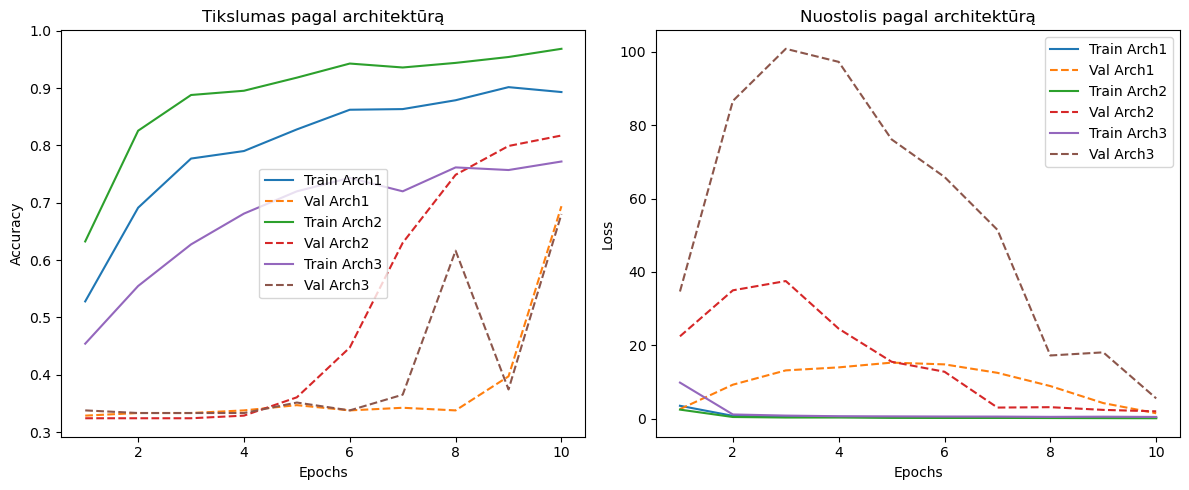

In [7]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
for i, res in enumerate(arch_results):
    plt.plot(epoch_range[:len(res["train_acc_history"])], res["train_acc_history"], label=f"Train Arch{i+1}")
    plt.plot(epoch_range[:len(res["val_acc_history"])], res["val_acc_history"], '--', label=f"Val Arch{i+1}")
plt.xlabel("Epochs"); plt.ylabel("Accuracy")
plt.title("Tikslumas pagal architektūrą")
plt.legend()

plt.subplot(1,2,2)
for i, res in enumerate(arch_results):
    plt.plot(epoch_range[:len(res["train_loss_history"])], res["train_loss_history"], label=f"Train Arch{i+1}")
    plt.plot(epoch_range[:len(res["val_loss_history"])], res["val_loss_history"], '--', label=f"Val Arch{i+1}")
plt.xlabel("Epochs"); plt.ylabel("Loss")
plt.title("Nuostolis pagal architektūrą")
plt.legend()
plt.tight_layout()
plt.show()

Testing dropout_final=0.0, lr=0.001, activation=relu
Epoch 1/10
55/55 - 18s - 330ms/step - accuracy: 0.4971 - loss: 4.5724 - val_accuracy: 0.3333 - val_loss: 92.5376
Epoch 2/10
55/55 - 18s - 328ms/step - accuracy: 0.7011 - loss: 0.7200 - val_accuracy: 0.3333 - val_loss: 124.2958
Epoch 3/10
55/55 - 20s - 366ms/step - accuracy: 0.8343 - loss: 0.4476 - val_accuracy: 0.3333 - val_loss: 111.5830
Epoch 4/10
55/55 - 20s - 355ms/step - accuracy: 0.8800 - loss: 0.3716 - val_accuracy: 0.3333 - val_loss: 80.3353
Epoch 5/10
55/55 - 19s - 346ms/step - accuracy: 0.9240 - loss: 0.2199 - val_accuracy: 0.3333 - val_loss: 45.0703
Epoch 6/10
55/55 - 20s - 362ms/step - accuracy: 0.9549 - loss: 0.1364 - val_accuracy: 0.3333 - val_loss: 27.9462
Epoch 7/10
55/55 - 19s - 348ms/step - accuracy: 0.9611 - loss: 0.1146 - val_accuracy: 0.3333 - val_loss: 13.7018
Epoch 8/10
55/55 - 22s - 399ms/step - accuracy: 0.9686 - loss: 0.1190 - val_accuracy: 0.7123 - val_loss: 1.1681
Epoch 9/10
55/55 - 24s - 433ms/step - accu

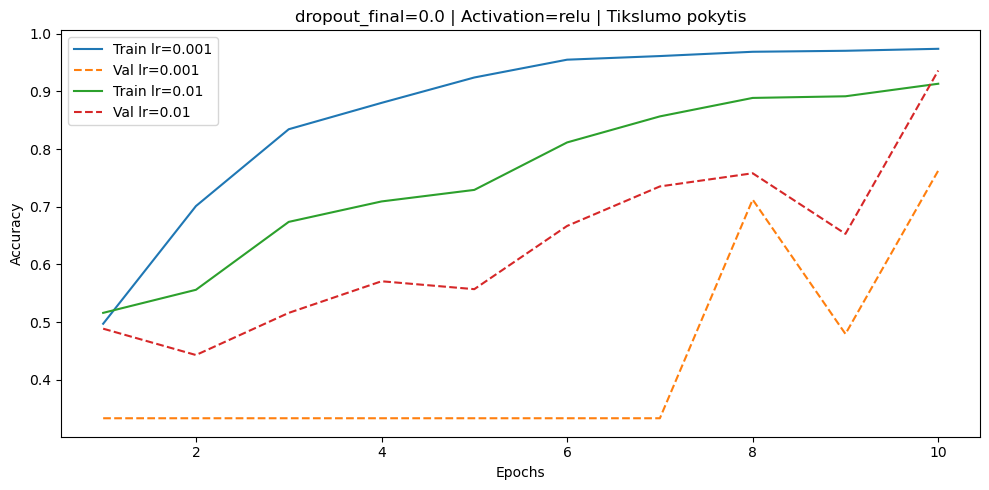

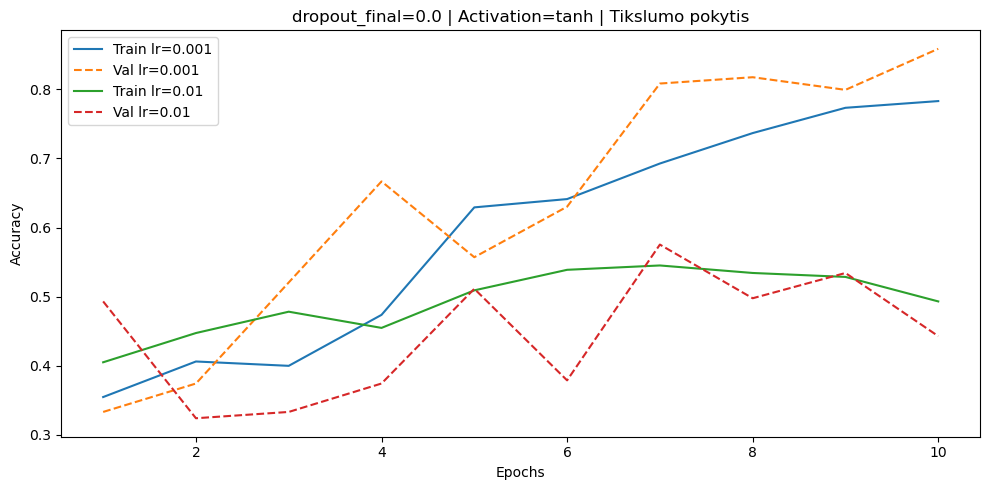

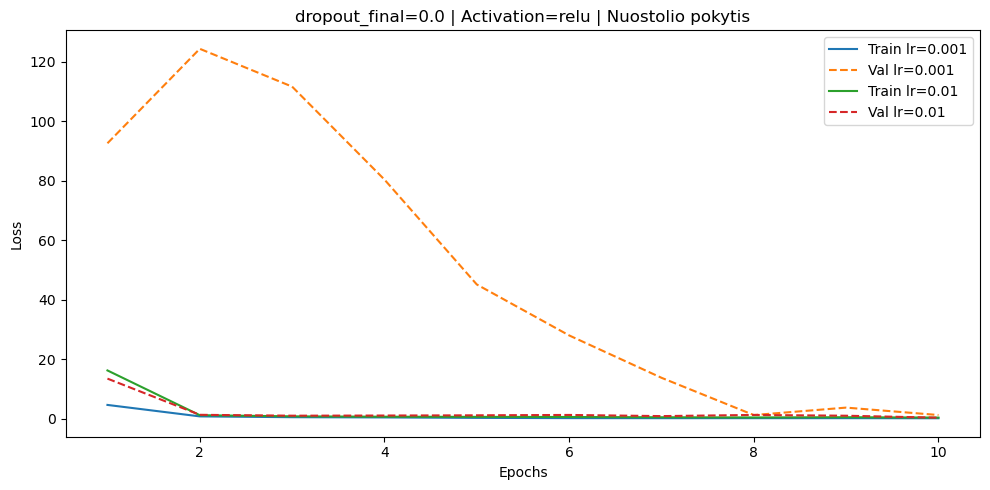

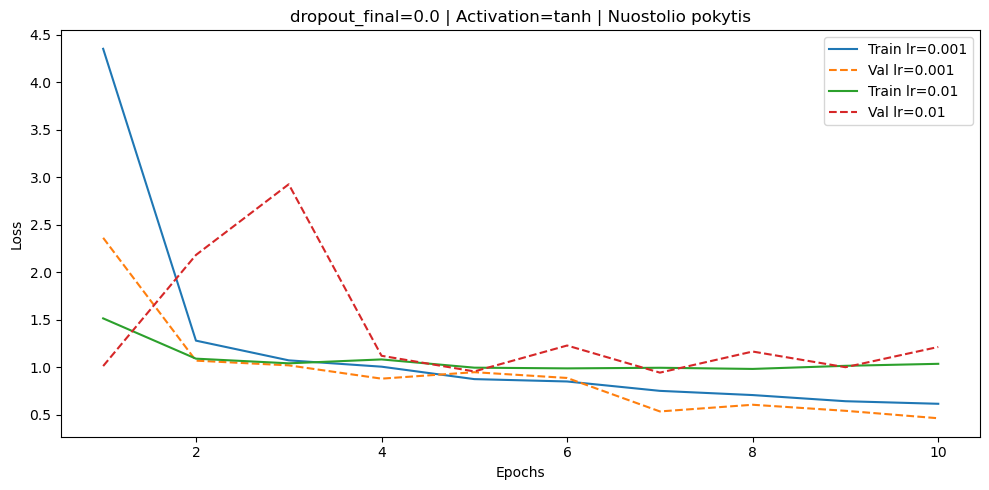

Testing dropout_final=0.25, lr=0.001, activation=relu
Epoch 1/10
55/55 - 24s - 434ms/step - accuracy: 0.6526 - loss: 3.0634 - val_accuracy: 0.3333 - val_loss: 42.3806
Epoch 2/10
55/55 - 25s - 455ms/step - accuracy: 0.8480 - loss: 0.4596 - val_accuracy: 0.3333 - val_loss: 58.8037
Epoch 3/10
55/55 - 24s - 430ms/step - accuracy: 0.9006 - loss: 0.3018 - val_accuracy: 0.3333 - val_loss: 50.7301
Epoch 4/10
55/55 - 22s - 405ms/step - accuracy: 0.9143 - loss: 0.2635 - val_accuracy: 0.3333 - val_loss: 34.0843
Epoch 5/10
55/55 - 22s - 393ms/step - accuracy: 0.9360 - loss: 0.1890 - val_accuracy: 0.3333 - val_loss: 20.0517
Epoch 6/10
55/55 - 23s - 413ms/step - accuracy: 0.9423 - loss: 0.1687 - val_accuracy: 0.3333 - val_loss: 11.0264
Epoch 7/10
55/55 - 22s - 397ms/step - accuracy: 0.9463 - loss: 0.1736 - val_accuracy: 0.3333 - val_loss: 10.1924
Epoch 8/10
55/55 - 21s - 385ms/step - accuracy: 0.9514 - loss: 0.1681 - val_accuracy: 0.5342 - val_loss: 6.1294
Epoch 9/10
55/55 - 21s - 381ms/step - accur

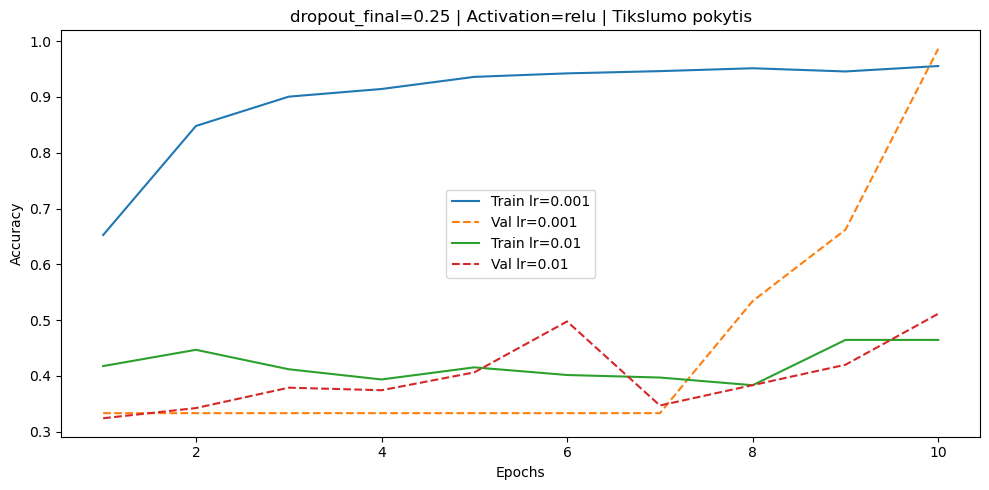

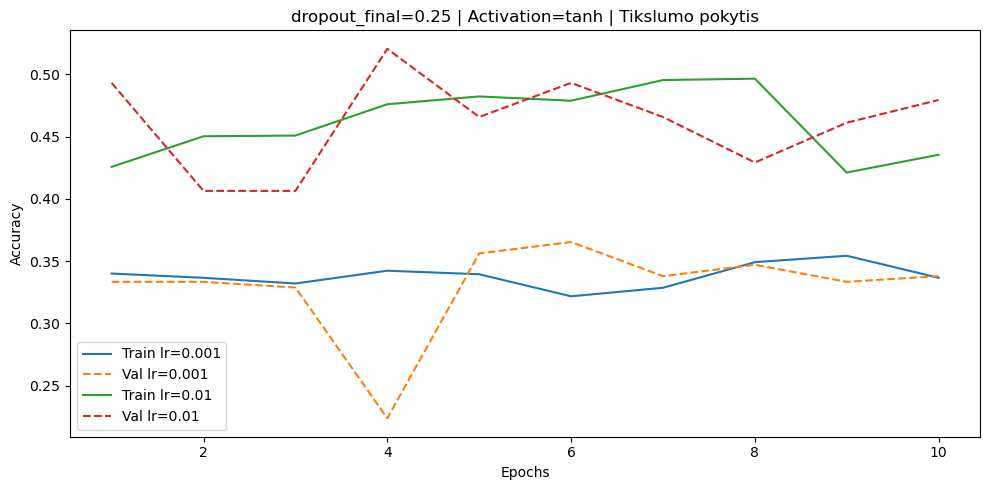

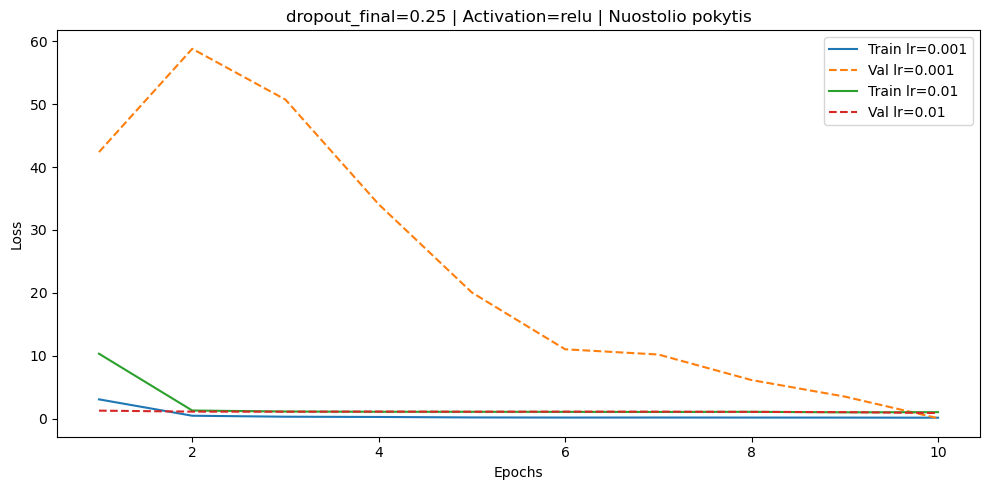

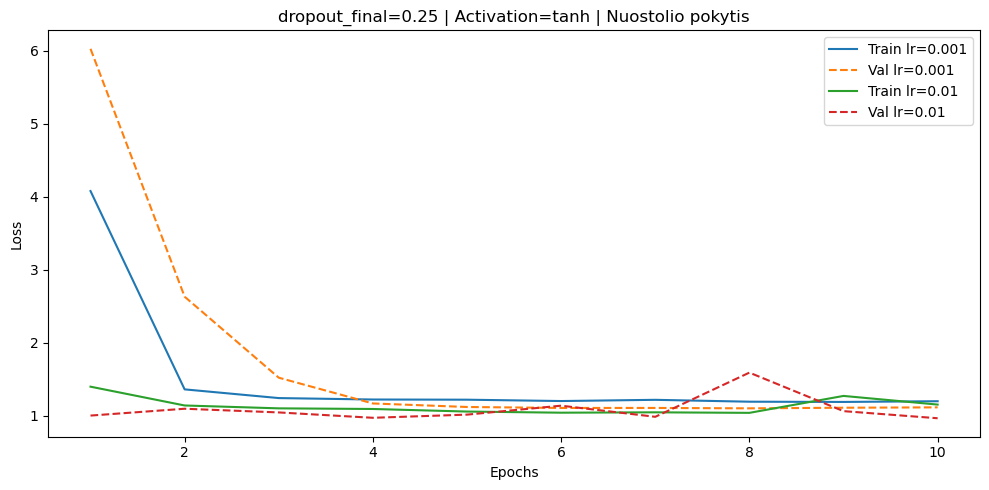

Testing batchnorm=True, lr=0.001, activation=relu
Epoch 1/10
55/55 - 25s - 454ms/step - accuracy: 0.5086 - loss: 2.8875 - val_accuracy: 0.3333 - val_loss: 16.0183
Epoch 2/10
55/55 - 23s - 413ms/step - accuracy: 0.7394 - loss: 0.6859 - val_accuracy: 0.3333 - val_loss: 16.6510
Epoch 3/10
55/55 - 22s - 404ms/step - accuracy: 0.8394 - loss: 0.4326 - val_accuracy: 0.3333 - val_loss: 15.2330
Epoch 4/10
55/55 - 22s - 407ms/step - accuracy: 0.8691 - loss: 0.3858 - val_accuracy: 0.3333 - val_loss: 14.2194
Epoch 5/10
55/55 - 22s - 408ms/step - accuracy: 0.8994 - loss: 0.2845 - val_accuracy: 0.3379 - val_loss: 18.1241
Epoch 6/10
55/55 - 22s - 405ms/step - accuracy: 0.9154 - loss: 0.2527 - val_accuracy: 0.3379 - val_loss: 13.9134
Epoch 7/10
55/55 - 22s - 404ms/step - accuracy: 0.9137 - loss: 0.2821 - val_accuracy: 0.4247 - val_loss: 6.7100
Epoch 8/10
55/55 - 22s - 404ms/step - accuracy: 0.9326 - loss: 0.2003 - val_accuracy: 0.5205 - val_loss: 5.7443
Epoch 9/10
55/55 - 22s - 406ms/step - accuracy: 

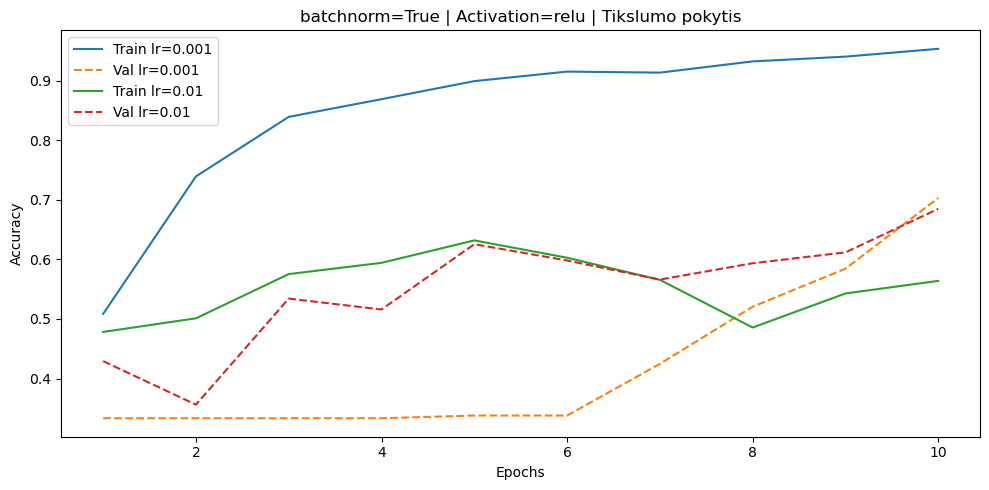

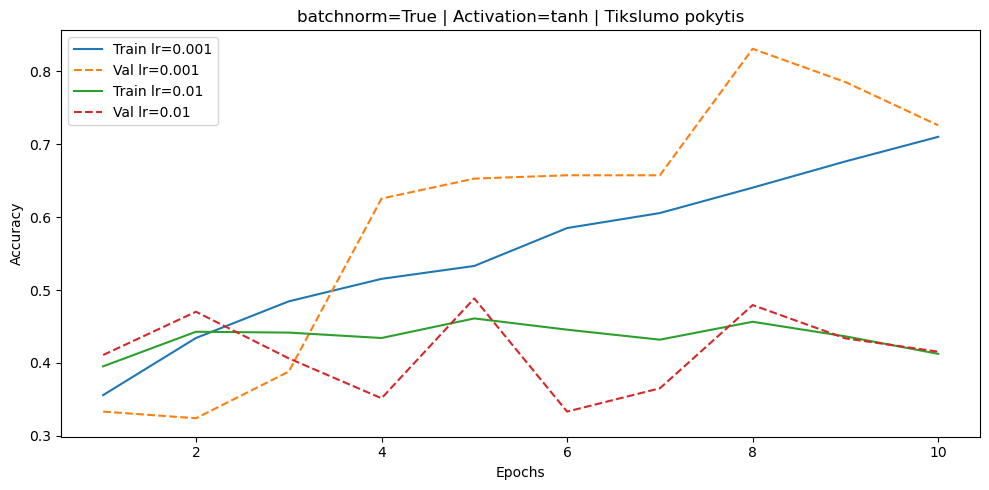

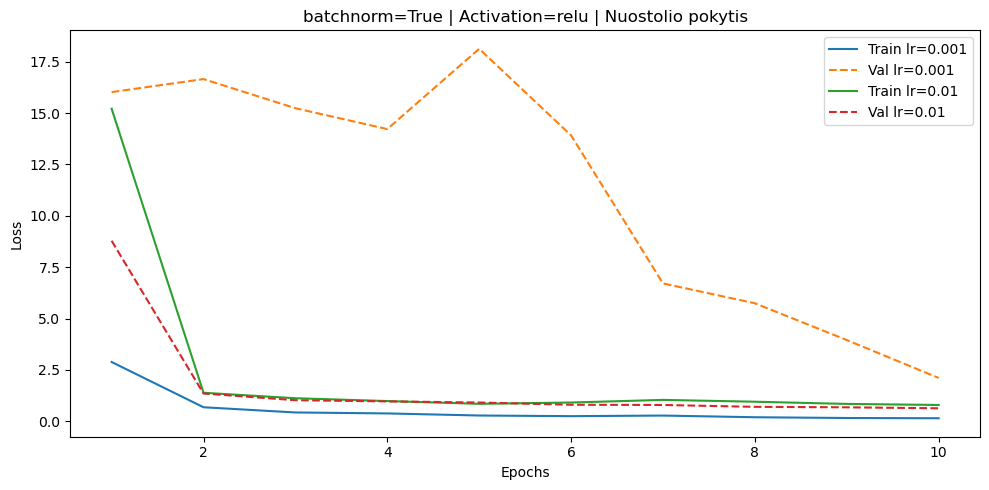

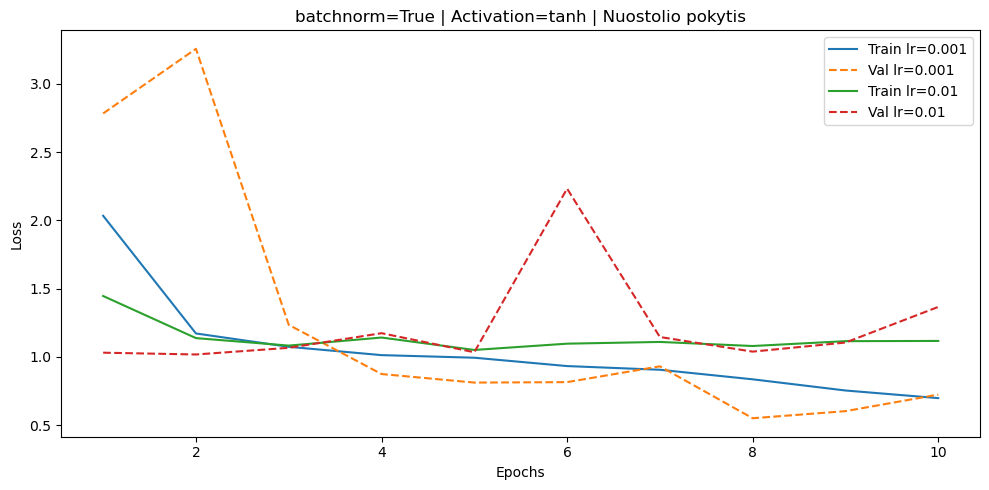

Testing batchnorm=False, lr=0.001, activation=relu
Epoch 1/10
55/55 - 17s - 307ms/step - accuracy: 0.3154 - loss: 1.2201 - val_accuracy: 0.3333 - val_loss: 1.0985
Epoch 2/10
55/55 - 16s - 288ms/step - accuracy: 0.4583 - loss: 1.0240 - val_accuracy: 0.6895 - val_loss: 0.9001
Epoch 3/10
55/55 - 16s - 283ms/step - accuracy: 0.5749 - loss: 0.9216 - val_accuracy: 0.7489 - val_loss: 0.8364
Epoch 4/10
55/55 - 15s - 281ms/step - accuracy: 0.6331 - loss: 0.8560 - val_accuracy: 0.7945 - val_loss: 0.7187
Epoch 5/10
55/55 - 15s - 279ms/step - accuracy: 0.7337 - loss: 0.7067 - val_accuracy: 0.8493 - val_loss: 0.3863
Epoch 6/10
55/55 - 15s - 280ms/step - accuracy: 0.8211 - loss: 0.4705 - val_accuracy: 0.9132 - val_loss: 0.3075
Epoch 7/10
55/55 - 15s - 278ms/step - accuracy: 0.8537 - loss: 0.3877 - val_accuracy: 0.9087 - val_loss: 0.2473
Epoch 8/10
55/55 - 15s - 279ms/step - accuracy: 0.8794 - loss: 0.3224 - val_accuracy: 0.8904 - val_loss: 0.2655
Epoch 9/10
55/55 - 15s - 281ms/step - accuracy: 0.877

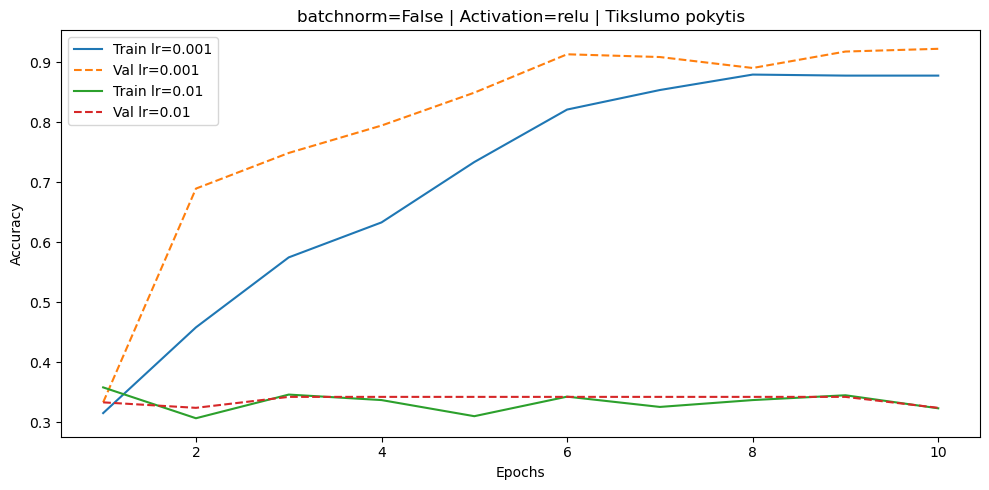

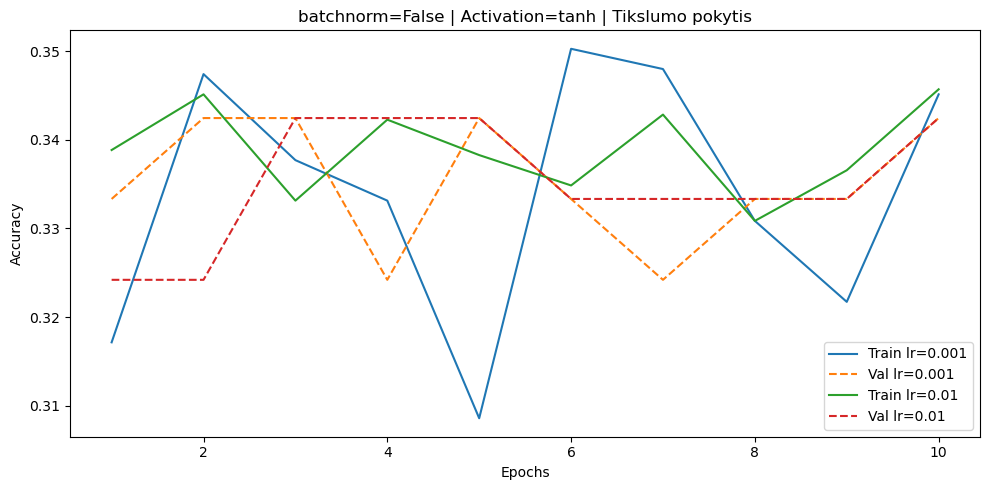

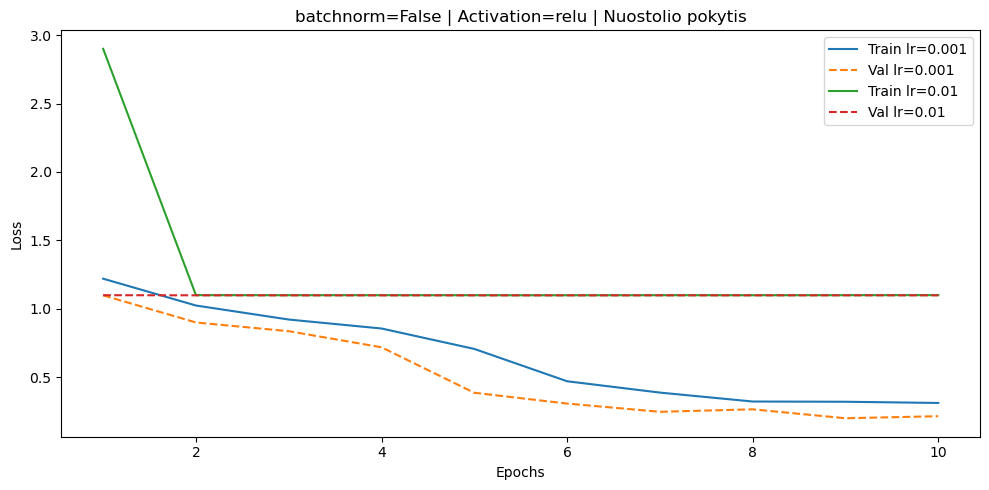

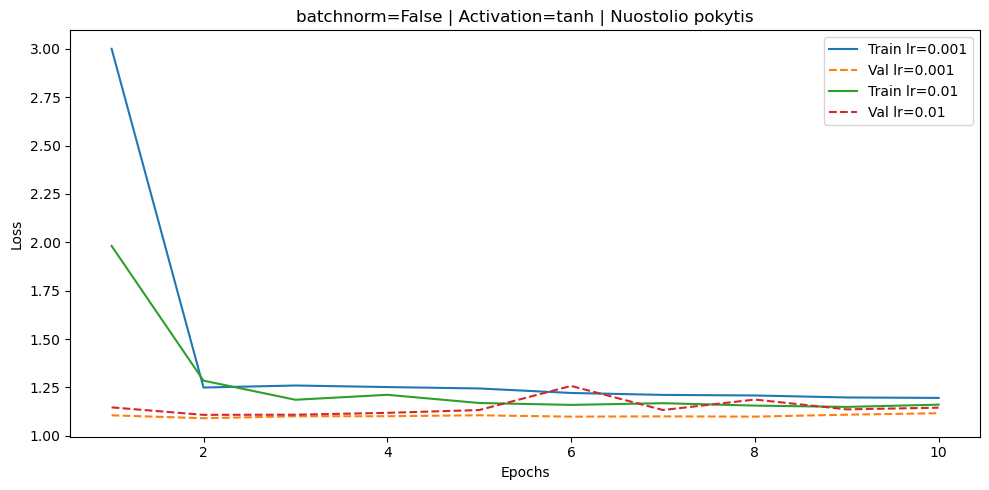

Testing optimizer_name=adam, lr=0.001, activation=relu
Epoch 1/10
55/55 - 26s - 479ms/step - accuracy: 0.5949 - loss: 2.3831 - val_accuracy: 0.3242 - val_loss: 51.8013
Epoch 2/10
55/55 - 26s - 478ms/step - accuracy: 0.7783 - loss: 0.5751 - val_accuracy: 0.3242 - val_loss: 67.3703
Epoch 3/10
55/55 - 25s - 446ms/step - accuracy: 0.8474 - loss: 0.4015 - val_accuracy: 0.3242 - val_loss: 60.5375
Epoch 4/10
55/55 - 25s - 462ms/step - accuracy: 0.8749 - loss: 0.3097 - val_accuracy: 0.3242 - val_loss: 44.2788
Epoch 5/10
55/55 - 25s - 461ms/step - accuracy: 0.9183 - loss: 0.2252 - val_accuracy: 0.3242 - val_loss: 25.7946
Epoch 6/10
55/55 - 33s - 602ms/step - accuracy: 0.9246 - loss: 0.1911 - val_accuracy: 0.3516 - val_loss: 13.0671
Epoch 7/10
55/55 - 32s - 581ms/step - accuracy: 0.9320 - loss: 0.1672 - val_accuracy: 0.5982 - val_loss: 6.5316
Epoch 8/10
55/55 - 27s - 484ms/step - accuracy: 0.9446 - loss: 0.1573 - val_accuracy: 0.5753 - val_loss: 4.9870
Epoch 9/10
55/55 - 26s - 482ms/step - accur

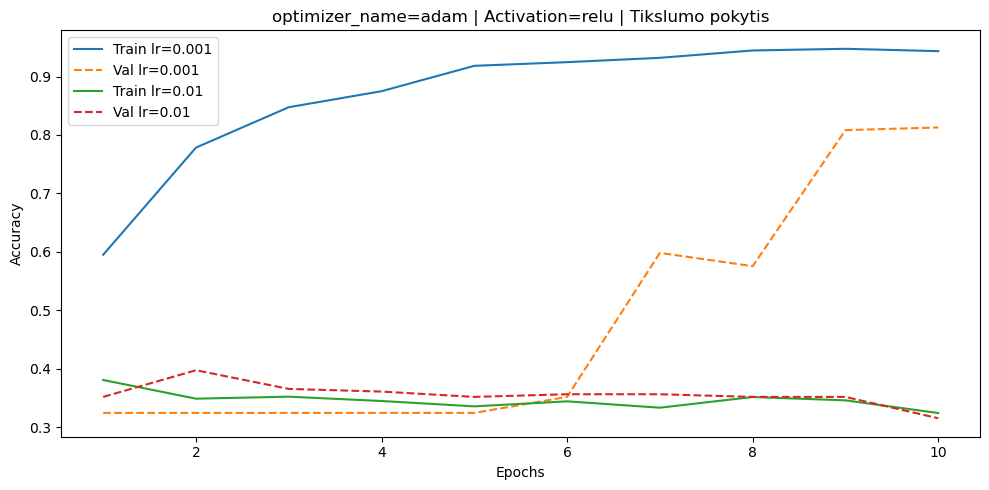

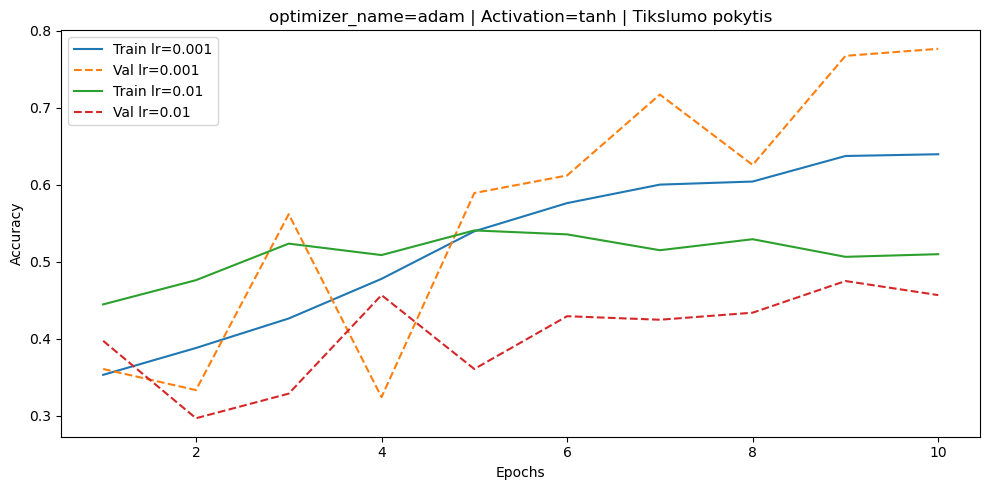

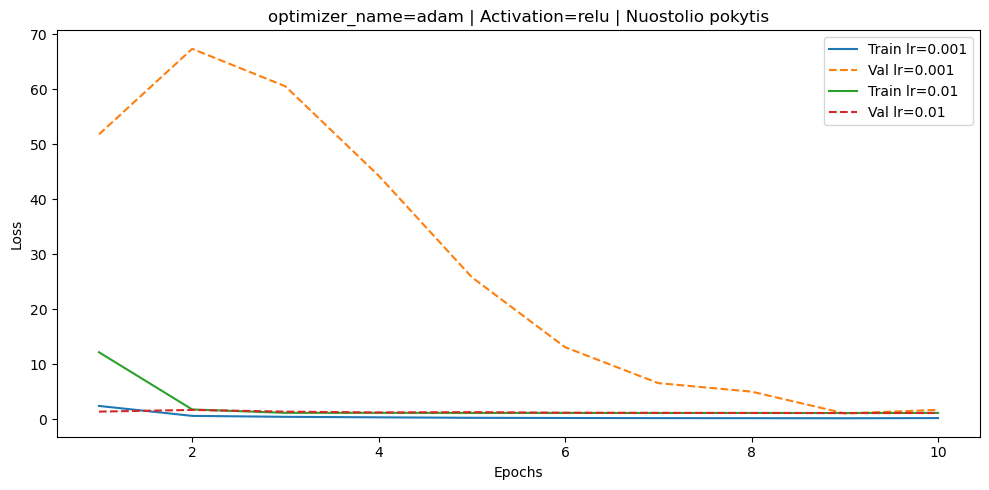

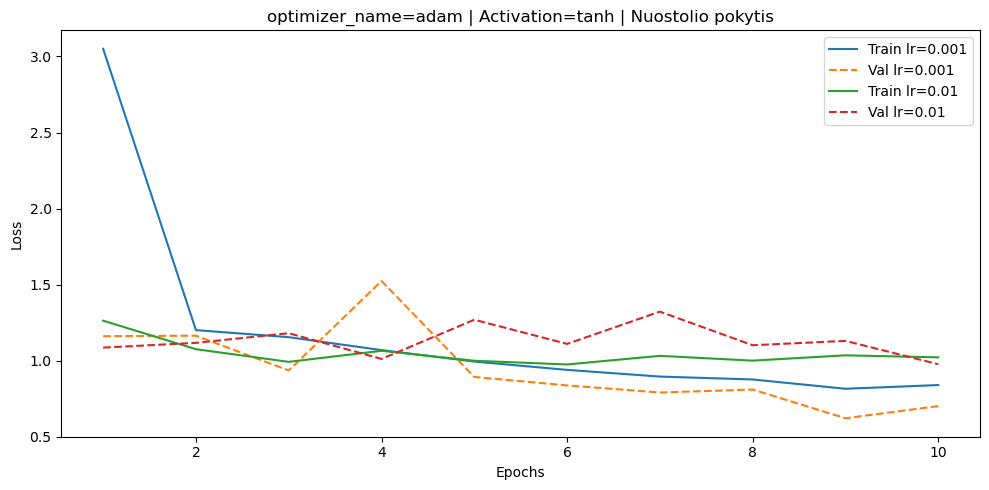

Testing optimizer_name=sgd, lr=0.001, activation=relu
Epoch 1/10
55/55 - 25s - 448ms/step - accuracy: 0.5040 - loss: 1.2802 - val_accuracy: 0.3242 - val_loss: 1.2431
Epoch 2/10
55/55 - 25s - 449ms/step - accuracy: 0.6829 - loss: 0.7562 - val_accuracy: 0.3242 - val_loss: 1.6828
Epoch 3/10
55/55 - 23s - 427ms/step - accuracy: 0.7669 - loss: 0.6098 - val_accuracy: 0.3242 - val_loss: 2.1778
Epoch 4/10
55/55 - 23s - 421ms/step - accuracy: 0.8034 - loss: 0.5059 - val_accuracy: 0.3333 - val_loss: 2.2009
Epoch 5/10
55/55 - 26s - 467ms/step - accuracy: 0.8297 - loss: 0.4379 - val_accuracy: 0.3333 - val_loss: 2.3863
Epoch 6/10
55/55 - 24s - 436ms/step - accuracy: 0.8440 - loss: 0.4206 - val_accuracy: 0.4840 - val_loss: 1.9707
Epoch 7/10
55/55 - 25s - 462ms/step - accuracy: 0.8714 - loss: 0.3671 - val_accuracy: 0.5662 - val_loss: 1.5324
Epoch 8/10
55/55 - 24s - 443ms/step - accuracy: 0.8869 - loss: 0.3334 - val_accuracy: 0.5982 - val_loss: 1.1763
Epoch 9/10
55/55 - 27s - 490ms/step - accuracy: 0.

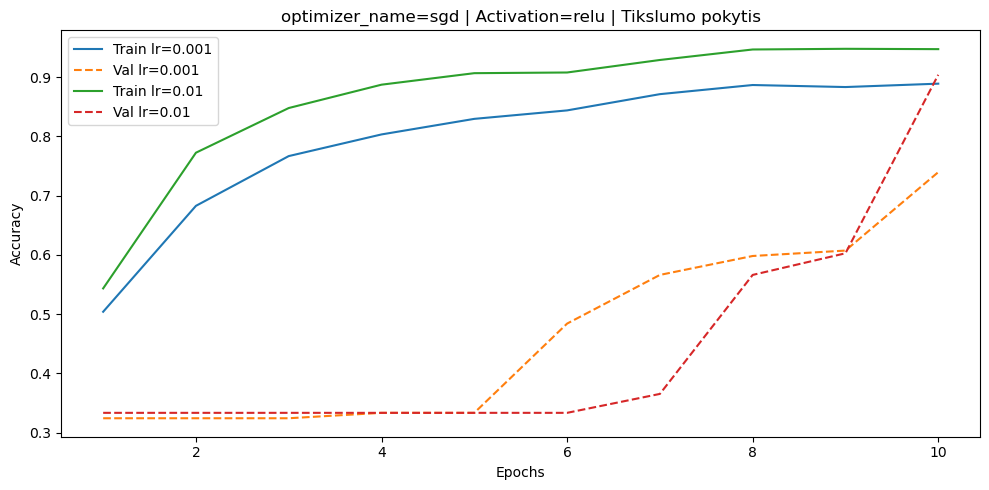

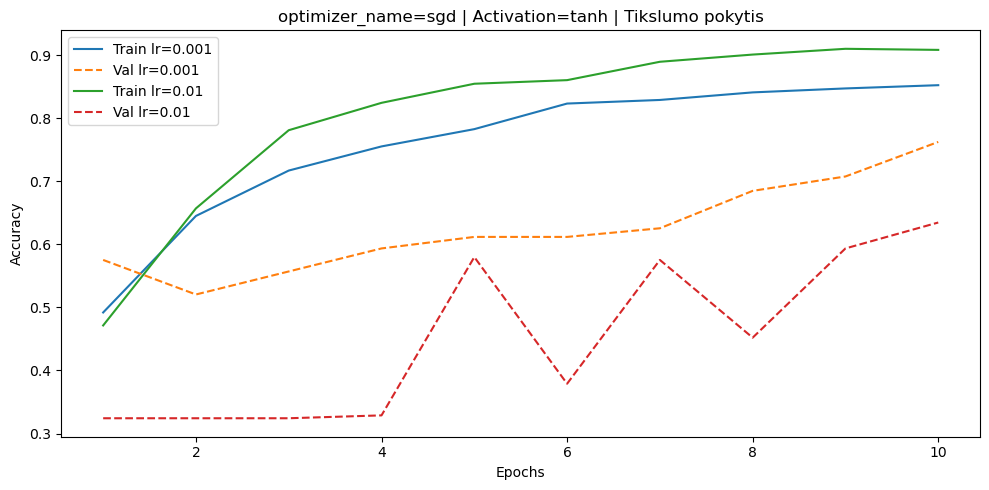

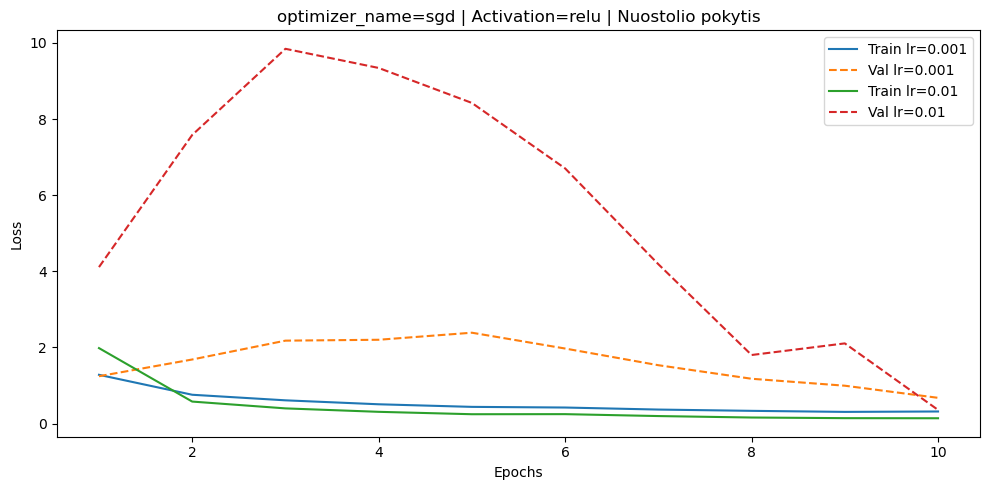

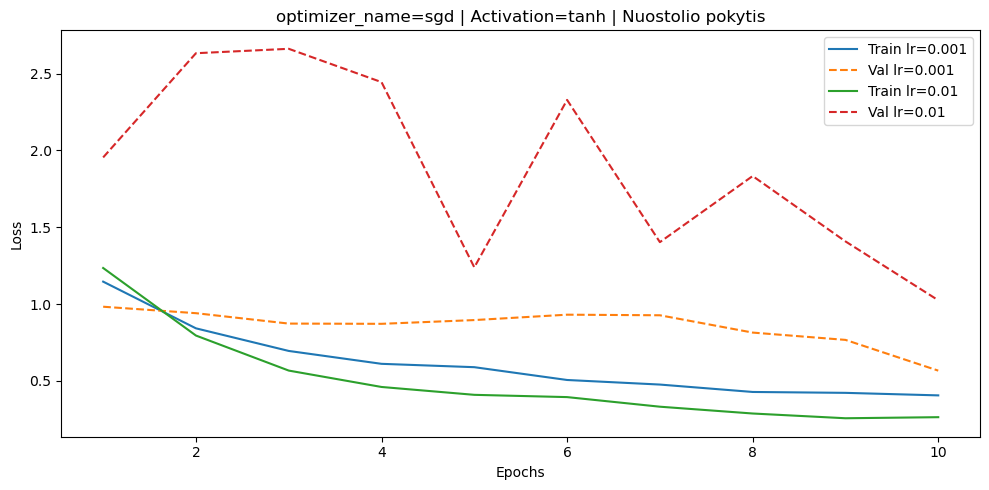

In [10]:
hyperparams = {
    "dropout_final": [0.0, 0.25],
    "batchnorm": [True, False],
    "optimizer_name": ["adam", "sgd"]
}

learning_rates = [0.001, 0.01]
activations = ["relu", "tanh"]

for param, values in hyperparams.items():
    for val in values:
        results = []
        settings = []

        for lr, act in product(learning_rates, activations):
            kwargs = {
                "conv_blocks": architectures[1],
                "dropout_final": 0.25,
                "activation": act,
                "batchnorm": True,
                "optimizer_name": "adam",
                "learning_rate": lr,
                "epochs": epochs
            }
            
            kwargs[param] = val

            print(f"Testing {param}={val}, lr={lr}, activation={act}")
            res = run_experiment(**kwargs)
            results.append(res)
            settings.append({"lr": lr, "act": act})

        for act in activations:
            plt.figure(figsize=(10, 5))
            for i, res in enumerate(results):
                if settings[i]["act"] == act:
                    lr = settings[i]["lr"]
                    plt.plot(epoch_range[:len(res["train_acc_history"])],
                             res["train_acc_history"], label=f"Train lr={lr}")
                    plt.plot(epoch_range[:len(res["val_acc_history"])],
                             res["val_acc_history"], '--', label=f"Val lr={lr}")
            plt.xlabel("Epochs")
            plt.ylabel("Accuracy")
            plt.title(f"{param}={val} | Activation={act} | Tikslumo pokytis")
            plt.legend()
            plt.tight_layout()
            plt.show()

        for act in activations:
            plt.figure(figsize=(10, 5))
            for i, res in enumerate(results):
                if settings[i]["act"] == act:
                    lr = settings[i]["lr"]
                    plt.plot(epoch_range[:len(res["train_loss_history"])],
                             res["train_loss_history"], label=f"Train lr={lr}")
                    plt.plot(epoch_range[:len(res["val_loss_history"])],
                             res["val_loss_history"], '--', label=f"Val lr={lr}")
            plt.xlabel("Epochs")
            plt.ylabel("Loss")
            plt.title(f"{param}={val} | Activation={act} | Nuostolio pokytis")
            plt.legend()
            plt.tight_layout()
            plt.show()

In [13]:
best_conv_blocks = architectures[1]
best_model_res = run_experiment(
    conv_blocks=best_conv_blocks,
    dropout_final=0.25,
    activation="relu",
    batchnorm=False,
    optimizer_name="adam",
    learning_rate=0.001,
    epochs=epochs,
    batch_size=config["batch_size"]
)

best_model = best_model_res["model"]

test_ds = make_dataset(fp_test, y_test, batch_size=config["batch_size"], shuffle=False, augment=False)

test_loss, test_acc = best_model.evaluate(test_ds, verbose=2)
print(f"\nTestavimo tikslumas: {test_acc*100:.2f}%")

y_pred_probs = best_model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test

cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:")
print(cm)

num_samples = 30
indices = []

for cls in range(len(classes)):
    cls_indices = np.where(y_test == cls)[0]
    indices.extend(np.random.choice(cls_indices, size=min(len(cls_indices), num_samples//len(classes)), replace=False))

indices = np.array(indices)
np.random.shuffle(indices)

print("\n30 testavimo pavyzdžių klasifikacija:")
for idx in indices:
    img_path = fp_test[idx]
    img = process_path(img_path, y_test[idx])[0]
    img_input = tf.expand_dims(img, axis=0)
    pred_class = np.argmax(best_model.predict(img_input), axis=1)[0]
    print(f"Failas: {img_path.split('/')[-1]}, Tikroji klasė: {classes[y_test[idx]]}, Prognozė: {classes[pred_class]}")

Epoch 1/10
55/55 - 26s - 466ms/step - accuracy: 0.4383 - loss: 1.1105 - val_accuracy: 0.7443 - val_loss: 0.9037
Epoch 2/10
55/55 - 21s - 383ms/step - accuracy: 0.7069 - loss: 0.7329 - val_accuracy: 0.8767 - val_loss: 0.3881
Epoch 3/10
55/55 - 24s - 442ms/step - accuracy: 0.8451 - loss: 0.4310 - val_accuracy: 0.8950 - val_loss: 0.3029
Epoch 4/10
55/55 - 22s - 403ms/step - accuracy: 0.8554 - loss: 0.3657 - val_accuracy: 0.9406 - val_loss: 0.1782
Epoch 5/10
55/55 - 20s - 372ms/step - accuracy: 0.8920 - loss: 0.3044 - val_accuracy: 0.9269 - val_loss: 0.1923
Epoch 6/10
55/55 - 21s - 377ms/step - accuracy: 0.8949 - loss: 0.2730 - val_accuracy: 0.9589 - val_loss: 0.1318
Epoch 7/10
55/55 - 21s - 375ms/step - accuracy: 0.9034 - loss: 0.2541 - val_accuracy: 0.9635 - val_loss: 0.1403
Epoch 8/10
55/55 - 20s - 372ms/step - accuracy: 0.9143 - loss: 0.2402 - val_accuracy: 0.9498 - val_loss: 0.1477
Epoch 9/10
55/55 - 21s - 378ms/step - accuracy: 0.9286 - loss: 0.2135 - val_accuracy: 0.9498 - val_loss: